# 11 — Correcciones de la extracción: la nueva línea de base

**Objetivo:** arreglar los tres problemas de la extracción de features que
encontramos en las notebooks 01 y 03, y medir qué cambia en los modelos. Al
terminar deberías poder:
- explicar las tres correcciones y por qué son errores y no decisiones;
- leer un diseño 2 × 2 (cada corrección sola y las dos juntas) para saber qué
  causó cada cambio;
- usar el **bootstrap pareado** para decidir si la diferencia entre dos
  versiones puede ser azar;
- responder la duda de las notebooks 08 y 09 sobre los máximos y mínimos de
  MFCC;
- describir la nueva línea de base, contra la que se comparan las notebooks
  12 (filtros), 13 (ritmo) y 14 (umbral).

Las reglas son las de la notebook 10, con los cuatro modelos elegidos por su
tipo: regresión logística, SVM-RBF, random forest y XGBoost (corregido),
todos con `class_weight`. Validación cruzada estratificada de 5 particiones,
repetida 3 veces; umbral 0,5; AUC con su intervalo, sensibilidad,
especificidad y exactitud balanceada; AUC por tipo de patología y control de
pseudo-casos.

*(La notebook tarda unos 12 minutos en correr entera; la sección 9 es la
más lenta.)*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.svm import SVC
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline   # el mismo pipeline de la tesis: escalado -> modelo
from src.features import load_metadata     # los metadatos con los IDs pulmonares reparados
from src.paths import AUDIO, OUT_DIR

# Avisos de convergencia y de versiones de las librerías: no cambian los resultados
warnings.filterwarnings("ignore")

NO_FEATURES = ["file_id", "label", "label_binary"]
SEMILLA = 0
REPETICIONES = 3
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}

# Colores de los gráficos
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})

## 1. Las tres correcciones

| # | Problema | Dónde lo vimos | Corrección |
|---|---|---|---|
| 1 | Los audios se cargan a 22.050 Hz, pero están grabados a 4000 Hz: todo lo que está por encima de 2000 Hz está vacío, y la mitad de las bandas mel mira esa zona | notebooks 01 y 03 | cargar a 4000 Hz, con tramas de la misma duración |
| 2 | librosa **centra** cada trama y, en los bordes, rellena con ceros lo que "falta": los máximos y mínimos pueden salir de ese relleno | notebook 03, sección 9.1 | `center=False`: cada trama empieza y termina dentro del audio |
| 3 | La planitud espectral da ~0 siempre | notebook 03, sección 9.2 | se arregla sola con la corrección 1 |

**Las tramas se piensan en tiempo.** La tesis usa tramas de 2048 muestras con
saltos de 512: a 22.050 Hz son **93 ms** y **23 ms**. A 4000 Hz, la misma
duración son **372 y 93 muestras**. En la notebook 03 dijimos "por ejemplo,
256 muestras (64 ms)"; elegimos 372 para que **lo único que cambie sea la
frecuencia de carga**: cada trama mira el mismo pedazo de sonido que en la
tesis. Además, la resolución en frecuencia queda igual: 4000 / 372 ≈
22.050 / 2048 ≈ 10,8 Hz entre dos puntos del espectro.

**Un ajuste que viene con la corrección 1: el contraste espectral.** El
contraste divide el espectro en octavas a partir de 200 Hz. A 22.050 Hz eran
7 bandas: 0–200, 200–400, 400–800, 800–1600, 1600–3200, 3200–6400 y
6400–11.025 Hz. Las dos últimas caen enteras en la zona vacía, y la quinta,
en su mayor parte. A 4000 Hz entran 5 bandas, y la quinta termina en 2000 Hz.
Por eso la tabla pasa de 105 a 101 features.

**¿Por qué son errores y no decisiones?** Elegir un filtro es una decisión:
hay argumentos a favor y en contra (notebook 02). Acá no los hay: medir una
zona donde no hay sonido, o un relleno de ceros que no es parte de la
grabación, no tiene ningún argumento clínico ni de la señal a favor. Por eso
la versión corregida se adopta **de antemano**, antes de ver los resultados.
Los resultados se miran para **entender** qué cambió, no para elegir.

**Una cosa por vez: el diseño 2 × 2.** Si aplicáramos las dos correcciones
juntas y el resultado cambiara, no sabríamos cuál lo causó (como cambiar dos
medicaciones a la vez). Por eso armamos cuatro versiones de las features:

| | con relleno en los bordes | sin relleno |
|---|---|---|
| **22.050 Hz** | **A** — la tesis | **B** — solo bordes |
| **4000 Hz** | **C** — solo 4000 Hz | **D** — las dos (la corregida) |

A contra B muestra el efecto de los bordes; A contra C, el de la frecuencia de
carga; A contra D, el de las dos juntas.

La función de extracción es la de la tesis (`src/features.py`), con los
parámetros de las tramas a la vista:

In [2]:
def extraer(y, sr, n_fft, salto, bandas_contraste, centrar):
    """Las features de src/features.py, con los parámetros de las tramas explícitos."""
    tramas = dict(n_fft=n_fft, hop_length=salto, center=centrar)
    f = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13, **tramas)
    for i, c in enumerate(mfcc, 1):
        f[f"mfcc_{i}_mean"], f[f"mfcc_{i}_std"] = c.mean(), c.std()
        f[f"mfcc_{i}_max"], f[f"mfcc_{i}_min"] = c.max(), c.min()
    delta = librosa.feature.delta(mfcc, width=9)
    for i, c in enumerate(delta, 1):
        f[f"mfcc_delta_{i}_mean"], f[f"mfcc_delta_{i}_std"] = c.mean(), c.std()
    for nombre, funcion in [("spectral_centroid", librosa.feature.spectral_centroid),
                            ("spectral_bandwidth", librosa.feature.spectral_bandwidth),
                            ("spectral_rolloff", librosa.feature.spectral_rolloff)]:
        s = funcion(y=y, sr=sr, **tramas)[0]
        f[f"{nombre}_mean"], f[f"{nombre}_std"] = s.mean(), s.std()
    contraste = librosa.feature.spectral_contrast(y=y, sr=sr, n_bands=bandas_contraste, **tramas)
    for i, c in enumerate(contraste, 1):
        f[f"spectral_contrast_{i}_mean"], f[f"spectral_contrast_{i}_std"] = c.mean(), c.std()
    s = librosa.feature.spectral_flatness(y=y, **tramas)[0]
    f["spectral_flatness_mean"], f["spectral_flatness_std"] = s.mean(), s.std()
    s = librosa.feature.zero_crossing_rate(y, frame_length=n_fft, hop_length=salto, center=centrar)[0]
    f["zcr_mean"], f["zcr_std"] = s.mean(), s.std()
    s = librosa.feature.rms(y=y, frame_length=n_fft, hop_length=salto, center=centrar)[0]
    f["rms_mean"], f["rms_std"], f["rms_max"] = s.mean(), s.std(), s.max()
    return {k: (v if np.isfinite(v) else 0.0) for k, v in f.items()}   # como en la tesis


# bandas_contraste: cuántas octavas sobre 200 Hz (librosa agrega una más, la de 0-200 Hz)
VERSIONES = {
    "A": dict(sr=22050, n_fft=2048, salto=512, bandas_contraste=6, centrar=True),
    "B": dict(sr=22050, n_fft=2048, salto=512, bandas_contraste=6, centrar=False),
    "C": dict(sr=4000, n_fft=372, salto=93, bandas_contraste=4, centrar=True),
    "D": dict(sr=4000, n_fft=372, salto=93, bandas_contraste=4, centrar=False),
}
ETIQUETA = {"A": "A — la tesis", "B": "B — solo bordes", "C": "C — solo 4000 Hz", "D": "D — corregida"}

## 2. Extraer las cuatro versiones

Cargamos cada audio dos veces (a 22.050 Hz como la tesis, y a 4000 Hz, su
frecuencia original, sin remuestrear) y extraemos las cuatro versiones.
Después verificamos que la versión A reproduzca el CSV de la tesis que usamos
en las notebooks 03 a 10. *(Tarda alrededor de un minuto.)*

In [3]:
hs_meta, ls_meta = load_metadata()
META = {"LS": (ls_meta, "Lung Sound ID", "Lung Sound Type"),
        "HS": (hs_meta, "Heart Sound ID", "Heart Sound Type")}

inicio = time.time()
audios, tablas = {}, {}
for subset, (meta, col_id, col_tipo) in META.items():
    rutas = {fid: AUDIO[subset] / f"{fid}.wav" for fid in meta[col_id]}
    assert all(librosa.get_samplerate(r) == 4000 for r in rutas.values())   # todos grabados a 4000 Hz
    for sr in [22050, 4000]:
        audios[(subset, sr)] = {fid: librosa.load(r, sr=sr)[0] for fid, r in rutas.items()}
    for v, parametros in VERSIONES.items():
        p = dict(parametros)
        sr = p.pop("sr")
        filas = [{**extraer(audios[(subset, sr)][fila[col_id]], sr, **p), "file_id": fila[col_id],
                  "label": fila[col_tipo], "label_binary": int(fila["binary_label"])}
                 for _, fila in meta.iterrows()]
        tablas[(subset, v)] = pd.DataFrame(filas)
    print(f"{NOMBRE[subset]}: {len(meta)} grabaciones, 4 versiones "
          f"({tablas[(subset, 'A')].shape[1] - 3} y {tablas[(subset, 'D')].shape[1] - 3} features)")
print(f"({time.time() - inicio:.0f} segundos)")

for subset in META:
    tesis = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv").set_index("file_id")
    a = tablas[(subset, "A")].set_index("file_id").loc[tesis.index, tesis.columns]
    numericas = tesis.columns.drop(["label", "label_binary"])
    diferencia = ((a[numericas] - tesis[numericas]).abs() / (tesis[numericas].abs() + 1e-12)).max().max()
    print(f"{NOMBRE[subset]}: versión A contra el CSV de la tesis -> diferencia relativa máxima {diferencia:.0e}")

Pulmonares: 50 grabaciones, 4 versiones (105 y 101 features)


Cardíacos: 50 grabaciones, 4 versiones (105 y 101 features)
(67 segundos)
Pulmonares: versión A contra el CSV de la tesis -> diferencia relativa máxima 6e-08
Cardíacos: versión A contra el CSV de la tesis -> diferencia relativa máxima 6e-08


La versión A reproduce las features de la tesis, salvo diferencias de
redondeo (librosa calcula con unas 7 cifras significativas): partimos de los
mismos datos que la notebook 10.

## 3. ¿Se arreglaron los problemas?

### 3.1 Los bordes

Repetimos la cuenta de la notebook 03: en qué porcentaje de los casos el
mínimo y el máximo de cada MFCC caen en las 3 primeras o las 3 últimas
tramas de la grabación. Si fuera al azar, sería ~1 % (6 tramas de ~645).

In [4]:
def mfcc_por_trama(subset, v, file_id):
    p = VERSIONES[v]
    return librosa.feature.mfcc(y=audios[(subset, p["sr"])][file_id], sr=p["sr"], n_mfcc=13,
                                n_fft=p["n_fft"], hop_length=p["salto"], center=p["centrar"])


def en_el_borde(indices, n_tramas, k=3):
    return (indices < k) | (indices >= n_tramas - k)


filas = {}
for subset, (meta, col_id, _) in META.items():
    for v in VERSIONES:
        n_min = n_max = total = 0
        for fid in meta[col_id]:
            m = mfcc_por_trama(subset, v, fid)
            n_min += en_el_borde(m.argmin(axis=1), m.shape[1]).sum()
            n_max += en_el_borde(m.argmax(axis=1), m.shape[1]).sum()
            total += m.shape[0]
        filas.setdefault(ETIQUETA[v], {})[(NOMBRE[subset], "mínimos")] = f"{100 * n_min / total:.0f} %"
        filas[ETIQUETA[v]][(NOMBRE[subset], "máximos")] = f"{100 * n_max / total:.0f} %"
print("Mínimos y máximos de los MFCC que caen en las tramas del borde (por azar: ~1 %)")
print(pd.DataFrame(filas).T.to_string())

Mínimos y máximos de los MFCC que caen en las tramas del borde (por azar: ~1 %)
                 Pulmonares         Cardíacos        
                    mínimos máximos   mínimos máximos
A — la tesis           19 %    11 %      21 %     9 %
B — solo bordes         1 %     1 %       2 %     1 %
C — solo 4000 Hz       11 %     7 %      10 %     5 %
D — corregida           2 %     2 %       1 %     1 %


Con relleno (A y C), entre el 5 % y el 21 % de los mínimos y máximos salen de
los bordes: entre 5 y 20 veces más que por azar. Sin relleno (B y D) quedan
en 1–2 %, lo esperable por azar.

Así se ve en una grabación. Comparamos A y B, que tienen la misma definición
de MFCC y solo difieren en el relleno. Para que las tramas coincidan en el
tiempo, ubicamos cada una en su centro.

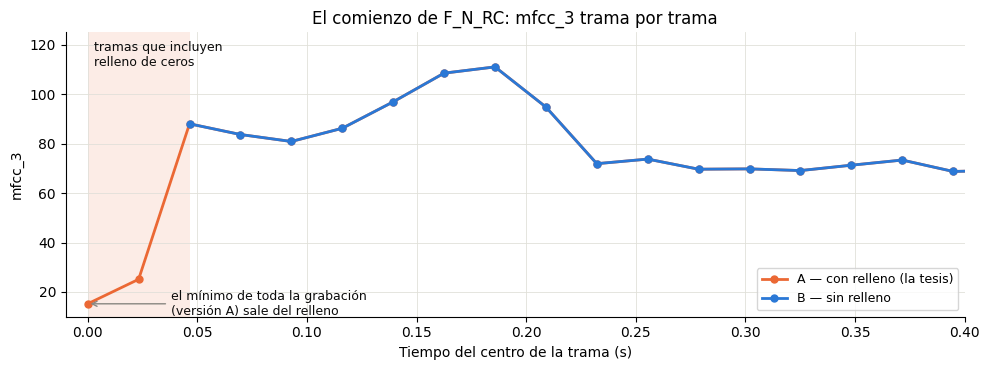

In [5]:
hs_ids = META["HS"][0][META["HS"][1]]
ejemplo = next(fid for fid in hs_ids if fid.split("_")[1] == "N"
               and mfcc_por_trama("HS", "A", fid)[2].argmin() < 3)   # un normal cuyo mínimo de mfcc_3 está en el borde
con_relleno = mfcc_por_trama("HS", "A", ejemplo)[2]
sin_relleno = mfcc_por_trama("HS", "B", ejemplo)[2]
t_con = np.arange(len(con_relleno)) * 512 / 22050               # centrada: la trama t está centrada en t·salto
t_sin = (np.arange(len(sin_relleno)) * 512 + 1024) / 22050      # sin centrar: empieza en t·salto

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(0, 1024 / 22050, color=NARANJA, alpha=0.12, lw=0)
ax.text(0.003, 0.97, "tramas que incluyen\nrelleno de ceros", transform=ax.get_xaxis_transform(),
        va="top", fontsize=9, color=TINTA)
ax.plot(t_con, con_relleno, "o-", color=NARANJA, ms=5, lw=2, label="A — con relleno (la tesis)")
ax.plot(t_sin, sin_relleno, "o-", color=AZUL, ms=5, lw=2, label="B — sin relleno")
i_min = con_relleno.argmin()
ax.annotate("el mínimo de toda la grabación\n(versión A) sale del relleno", (t_con[i_min], con_relleno[i_min]),
            xytext=(60, 0), textcoords="offset points", va="center", fontsize=9, color=TINTA,
            arrowprops=dict(arrowstyle="->", color=GRIS))
ax.set(xlim=(-0.01, 0.4), xlabel="Tiempo del centro de la trama (s)", ylabel="mfcc_3",
       title=f"El comienzo de {ejemplo}: mfcc_3 trama por trama")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()

Las dos curvas coinciden en todas las tramas salvo las primeras: en la versión
A, las tramas que incluyen el relleno dan un valor inventado, que acá termina
siendo **el mínimo de toda la grabación**. Eso es lo que guardaba la feature
`mfcc_3_min`.

### 3.2 La planitud

In [6]:
filas = {ETIQUETA[v]: {NOMBRE[s]: tablas[(s, v)]["spectral_flatness_mean"].median() for s in META}
         for v in VERSIONES}
print("Planitud media (mediana entre grabaciones)")
print(pd.DataFrame(filas).T.map(lambda x: f"{x:.6f}").to_string())

Planitud media (mediana entre grabaciones)
                 Pulmonares Cardíacos
A — la tesis       0.000003  0.000003
B — solo bordes    0.000001  0.000000
C — solo 4000 Hz   0.001107  0.000989
D — corregida      0.001017  0.000874


A 22.050 Hz la planitud es ~0,000003: la zona vacía la hunde (notebook 03). A
4000 Hz es unas 300 veces mayor y puede variar entre grabaciones.

### 3.3 ¿Qué features cambiaron?

Para cada feature, calculamos la correlación entre su valor en la versión A y
en otra versión, grabación por grabación. Una correlación cercana a 1 quiere
decir que la feature casi no cambió (ordena las grabaciones igual). Mostramos
la mediana por familia de features.

In [7]:
def familia(feature):
    for prefijo in ["mfcc_delta", "mfcc", "spectral_centroid", "spectral_bandwidth", "spectral_rolloff",
                    "spectral_contrast", "spectral_flatness", "zcr", "rms"]:
        if feature.startswith(prefijo):
            return prefijo


def correlaciones(subset, v):
    a, otra = tablas[(subset, "A")], tablas[(subset, v)]
    comunes = [c for c in a.columns if c in otra.columns and c not in NO_FEATURES]
    return pd.Series({c: np.corrcoef(a[c], otra[c])[0, 1] for c in comunes})


resumen = {}
for subset in META:
    for v, titulo in [("B", "A vs B (bordes)"), ("D", "A vs D (las dos)")]:
        r = correlaciones(subset, v)
        resumen[(NOMBRE[subset], titulo)] = r.groupby(r.index.map(familia)).median()
        print(f"{NOMBRE[subset]}, {titulo}: {(r < 0.9).sum()} de {len(r)} features con correlación < 0,9")
print()
print(pd.DataFrame(resumen).round(2).sort_values((NOMBRE["HS"], "A vs D (las dos)")).to_string())

Pulmonares, A vs B (bordes): 12 de 105 features con correlación < 0,9
Pulmonares, A vs D (las dos): 80 de 101 features con correlación < 0,9
Cardíacos, A vs B (bordes): 22 de 105 features con correlación < 0,9
Cardíacos, A vs D (las dos): 83 de 101 features con correlación < 0,9

                        Pulmonares                        Cardíacos                 
                   A vs B (bordes) A vs D (las dos) A vs B (bordes) A vs D (las dos)
spectral_flatness             0.34             0.34            0.13             0.07
mfcc                          1.00             0.12            1.00             0.28
mfcc_delta                    0.96             0.20            0.91             0.30
spectral_bandwidth            0.66             0.63            0.55             0.57
spectral_rolloff              0.98             0.98            0.89             0.89
spectral_centroid             0.99             0.99            0.91             0.91
spectral_contrast             1.00     

**Cómo leerla:**
- **Sacar el relleno** (A contra B) cambia de verdad unas pocas features (22
  de 105 en cardíacos, 12 en pulmonares): algunos mínimos, máximos y desvíos.
  Por eso la mayoría de las medianas por familia queda cerca de 1. Las
  excepciones son la planitud (a 22.050 Hz vale ~0, y el relleno la domina) y
  el ancho de banda: su desvío (`spectral_bandwidth_std`) cambia casi por
  completo, porque lo dominaban las dos o tres tramas con relleno.
- **Pasar a 4000 Hz** (A contra D) cambia casi por completo los **MFCC** y
  sus deltas: son otros números, porque ahora describen solo la zona con
  sonido. También cambia la planitud. El volumen (RMS), los cruces por cero, el
  centroide, el roll-off y el contraste quedan casi iguales: no dependían de
  la zona vacía, que tiene una energía prácticamente nula. (El ancho de banda
  cambia por su desvío, por el relleno, como en A contra B.)

## 4. ¿Qué cambia en los modelos?

Entrenamos los cuatro modelos con las cuatro versiones en los dos
subconjuntos, con las mismas reglas de la notebook 10. *(Esta celda tarda unos
un minuto y medio.)*

In [8]:
def modelos(y):
    """Los cuatro modelos de la notebook 10 (versión final, con class_weight)."""
    peso_xgb = (y == 0).sum() / (y == 1).sum()   # el "class_weight" de XGBoost (corrección de la notebook 10)
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"),
                                             "class_weight"),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight="balanced"), "class_weight"),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                              random_state=SEMILLA), "class_weight"),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso_xgb, eval_metric="logloss",
                                               random_state=SEMILLA, n_jobs=1), "class_weight"),
    }


MODELOS = ["Regresión logística", "SVM-RBF", "Random forest", "XGBoost"]


def puntajes(modelo, X, y, cv, grupos=None):
    """Probabilidad de 'patológico' out-of-fold (para el SVM, su puntaje por una sigmoide fija, notebook 10)."""
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def prob_validacion(modelo, X, y, repeticiones=REPETICIONES):
    return [puntajes(modelo, X, y, StratifiedKFold(5, shuffle=True, random_state=s)) for s in range(repeticiones)]


def metricas(y, probs, umbral=0.5):
    """AUC, sensibilidad, especificidad y exactitud balanceada, promediadas entre repeticiones."""
    filas = []
    for p in probs:
        tn, fp, fn, tp = confusion_matrix(y, p >= umbral, labels=[0, 1]).ravel()
        sens, esp = tp / (tp + fn), tn / (tn + fp)
        filas.append({"AUC": roc_auc_score(y, p), "sens.": sens, "esp.": esp, "exact. bal.": (sens + esp) / 2})
    return pd.DataFrame(filas).mean()


def datos(subset, v):
    df = tablas[(subset, v)]
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values   # género_tipo
    return df.drop(columns=NO_FEATURES), df["label_binary"].values, caso, df["label"].values


inicio = time.time()
probs = {}   # (subconjunto, versión, modelo) -> predicciones out-of-fold de cada repetición
for subset in META:
    for v in VERSIONES:
        X, y, caso, tipo = datos(subset, v)
        for nombre, modelo in modelos(y).items():
            probs[(subset, v, nombre)] = prob_validacion(modelo, X, y)
    print(f"{NOMBRE[subset]}: listo")
print(f"({time.time() - inicio:.0f} segundos)")


def auc(subset, v, nombre):
    y = datos(subset, v)[1]
    return np.mean([roc_auc_score(y, p) for p in probs[(subset, v, nombre)]])


for subset in META:
    t = pd.DataFrame({ETIQUETA[v]: {n: auc(subset, v, n) for n in MODELOS} for v in VERSIONES})
    print(f"\n{NOMBRE[subset]}: AUC por grabación")
    print(t.round(3).to_string())

Pulmonares: listo


Cardíacos: listo
(90 segundos)

Pulmonares: AUC por grabación
                     A — la tesis  B — solo bordes  C — solo 4000 Hz  D — corregida
Regresión logística         1.000            1.000             0.996          0.999
SVM-RBF                     0.977            0.971             0.979          0.975
Random forest               0.949            0.959             0.946          0.926
XGBoost                     0.931            0.937             0.890          0.868



Cardíacos: AUC por grabación
                     A — la tesis  B — solo bordes  C — solo 4000 Hz  D — corregida
Regresión logística         0.682            0.768             0.822          0.827
SVM-RBF                     0.730            0.770             0.824          0.833
Random forest               0.785            0.803             0.807          0.823
XGBoost                     0.822            0.795             0.745          0.752


El mismo resultado en un gráfico, solo con la versión de la tesis (A) y la
corregida (D):

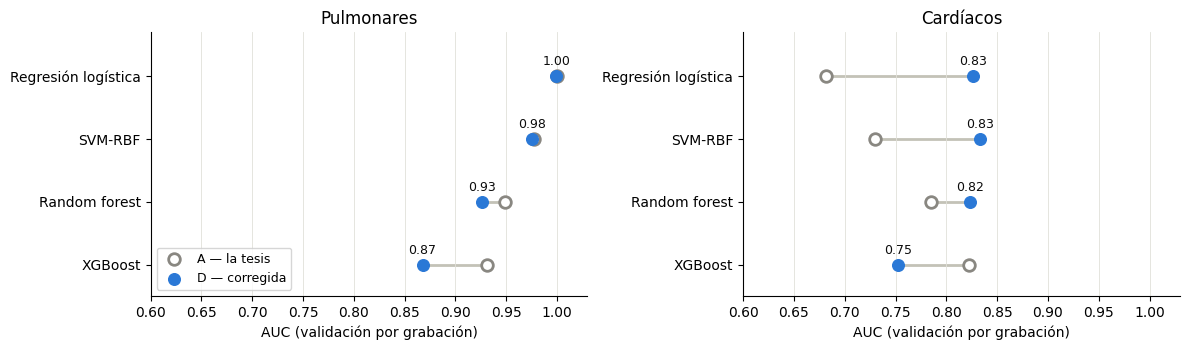

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
for ax, subset in zip(axes, META):
    for i, nombre in enumerate(MODELOS):
        a, d = auc(subset, "A", nombre), auc(subset, "D", nombre)
        ax.plot([a, d], [i, i], color="#c3c2b7", lw=2, zorder=1)
        ax.scatter(a, i, s=70, facecolor="white", edgecolor=GRIS, lw=2, zorder=2,
                   label=ETIQUETA["A"] if i == 0 else None)
        ax.scatter(d, i, s=70, color=AZUL, zorder=3, label=ETIQUETA["D"] if i == 0 else None)
        ax.annotate(f"{d:.2f}", (d, i), xytext=(0, 8), textcoords="offset points", ha="center",
                    fontsize=9, color=TINTA)
    ax.set(yticks=range(len(MODELOS)), xlim=(0.6, 1.03), ylim=(len(MODELOS) - 0.5, -0.7),
           title=NOMBRE[subset], xlabel="AUC (validación por grabación)")
    ax.set_yticklabels(MODELOS)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower left", fontsize=9)
fig.tight_layout()

**Cómo leerlo:**

**Pulmonares: casi nada cambia.** La regresión logística sigue en ~1,00 y el
SVM-RBF en ~0,98. Los modelos de árboles bajan un poco (XGBoost, de 0,93 a
0,87). El resultado pulmonar de la tesis **no dependía** de estos errores.

**Cardíacos: los modelos lineales mejoran mucho.**
- La **regresión logística** pasa de 0,68 a 0,83 y el **SVM-RBF**, de 0,73 a
  0,83: de estar entre los peores a estar arriba.
- El **random forest** sube un poco (de 0,79 a 0,82).
- **XGBoost** baja (de 0,82 a 0,75).

Mirando las cuatro versiones de la regresión logística en cardíacos: sacar el
relleno solo (B) la lleva a 0,77, y cargar a 4000 Hz solo (C), a 0,82. La
mayor parte de la mejora viene de la frecuencia de carga; los bordes también
ayudan, pero lo que arreglan se superpone en parte.

Ahora las cuatro métricas, para la versión de la tesis y la corregida:

In [10]:
def ic_auc(y, probs_modelo, n=500):
    """IC 95 % bootstrap del AUC promedio entre repeticiones (remuestreando grabaciones, notebook 07)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(np.mean([roc_auc_score(y[m], p[m]) for p in probs_modelo]))
    return np.percentile(valores, [2.5, 97.5])


def tabla_metricas(subset, versiones):
    y = datos(subset, "A")[1]
    bloques = {}
    for v in versiones:
        bloque = pd.DataFrame({n: metricas(y, probs[(subset, v, n)]) for n in MODELOS}).T.round(2)
        intervalos = {n: ic_auc(y, probs[(subset, v, n)]) for n in MODELOS}
        bloque.insert(1, "IC 95 %", pd.Series({n: f"{a:.2f}–{b:.2f}" for n, (a, b) in intervalos.items()}))
        bloques[ETIQUETA[v]] = bloque
    return pd.concat(bloques, axis=1)


for subset in META:
    print(f"\n===== {NOMBRE[subset]} =====")
    print(tabla_metricas(subset, ["A", "D"]).to_string())


===== Pulmonares =====


                    A — la tesis                                    D — corregida                                   
                             AUC    IC 95 % sens.  esp. exact. bal.           AUC    IC 95 % sens.  esp. exact. bal.
Regresión logística         1.00  1.00–1.00  0.98  0.94        0.96          1.00  1.00–1.00  1.00  0.86        0.93
SVM-RBF                     0.98  0.94–1.00  0.98  0.72        0.85          0.98  0.92–1.00  0.98  0.83        0.91
Random forest               0.95  0.88–0.99  0.99  0.64        0.82          0.93  0.83–0.99  1.00  0.56        0.78
XGBoost                     0.93  0.85–0.98  0.91  0.75        0.83          0.87  0.70–0.98  0.91  0.75        0.83

===== Cardíacos =====


                    A — la tesis                                    D — corregida                                   
                             AUC    IC 95 % sens.  esp. exact. bal.           AUC    IC 95 % sens.  esp. exact. bal.
Regresión logística         0.68  0.48–0.87  0.84  0.41        0.62          0.83  0.61–0.97  0.86  0.70        0.78
SVM-RBF                     0.73  0.54–0.91  0.88  0.37        0.62          0.83  0.62–0.97  0.93  0.41        0.67
Random forest               0.79  0.65–0.91  0.98  0.07        0.53          0.82  0.68–0.94  0.98  0.00        0.49
XGBoost                     0.82  0.68–0.94  0.89  0.59        0.74          0.75  0.60–0.89  0.83  0.41        0.62


**Cómo leerla:**
- En **cardíacos**, la regresión logística corregida no solo ordena mejor:
  reconoce muchos más normales (especificidad de 0,41 a 0,70) y queda con la
  mejor exactitud balanceada (0,78). El **random forest** sigue sin reconocer
  normales con el umbral 0,5 (especificidad ~0): es el problema de escala de
  la notebook 09, que la extracción no arregla. Lo atacamos en la notebook 14.
- En **pulmonares**, el SVM-RBF reconoce más normales (de 0,72 a 0,83) y la
  regresión logística, algo menos (de 0,94 a 0,86: en promedio, un normal más
  mal clasificado por repetición).
- Los **intervalos** de cardíacos siguen siendo anchos y se superponen: no hay
  un ganador claro, igual que en la notebook 10.

Pero ¿la mejora de la regresión logística es real, o puede ser azar? Mirar si
los intervalos de A y D se superponen no alcanza para responderlo. La sección
siguiente explica por qué y cómo hacerlo.

## 5. ¿Mejora real o azar? El bootstrap pareado

El intervalo de cada versión refleja la pregunta "¿cuánto cambiaría el AUC con
otras 50 grabaciones parecidas?". Pero las dos versiones se evalúan con **las
mismas** 50 grabaciones: si una grabación es difícil, lo es para las dos. Al
comparar los intervalos por separado, esa variación compartida se cuenta dos
veces, y la comparación queda demasiado exigente.

El **bootstrap pareado** compara las dos versiones **sobre las mismas
grabaciones**:
1. remuestrear las 50 grabaciones (con reposición, como en la notebook 07);
2. calcular el AUC de cada versión **con ese mismo remuestreo** y restarlos;
3. repetir 1000 veces y tomar el intervalo del 95 % de las diferencias.

Si el intervalo de la diferencia **no incluye el 0**, es poco probable que la
diferencia sea azar. Es como comparar la presión de cada paciente antes y
después de un tratamiento, en vez de comparar dos grupos de pacientes
distintos: la variación entre pacientes se cancela.

In [11]:
def dif_pareada(y, p_nueva, p_vieja, n=1000):
    """Diferencia de AUC (nueva − vieja) e IC 95 % por bootstrap pareado (las mismas grabaciones)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(np.mean([roc_auc_score(y[m], p[m]) for p in p_nueva])
                           - np.mean([roc_auc_score(y[m], p[m]) for p in p_vieja]))
    observada = np.mean([roc_auc_score(y, p) for p in p_nueva]) - np.mean([roc_auc_score(y, p) for p in p_vieja])
    return observada, np.percentile(valores, [2.5, 97.5])


filas = []
for subset in META:
    y = datos(subset, "A")[1]
    for nombre in MODELOS:
        d, (bajo, alto) = dif_pareada(y, probs[(subset, "D", nombre)], probs[(subset, "A", nombre)])
        filas.append({"subconjunto": NOMBRE[subset], "modelo": nombre, "A (tesis)": auc(subset, "A", nombre),
                      "D (corregida)": auc(subset, "D", nombre), "diferencia D − A": d,
                      "IC 95 % de la diferencia": f"{bajo:+.3f} a {alto:+.3f}",
                      "¿incluye el 0?": "no" if bajo > 0 or alto < 0 else "sí"})
print(pd.DataFrame(filas).round(3).to_string(index=False))

subconjunto              modelo  A (tesis)  D (corregida)  diferencia D − A IC 95 % de la diferencia ¿incluye el 0?
 Pulmonares Regresión logística      1.000          0.999            -0.001          -0.004 a +0.000             sí
 Pulmonares             SVM-RBF      0.977          0.975            -0.002          -0.034 a +0.023             sí
 Pulmonares       Random forest      0.949          0.926            -0.023          -0.080 a +0.011             sí
 Pulmonares             XGBoost      0.931          0.868            -0.064          -0.175 a +0.008             sí
  Cardíacos Regresión logística      0.682          0.827             0.145          +0.026 a +0.267             no
  Cardíacos             SVM-RBF      0.730          0.833             0.103          -0.010 a +0.235             sí
  Cardíacos       Random forest      0.785          0.823             0.038          -0.036 a +0.122             sí
  Cardíacos             XGBoost      0.822          0.752            -0.

**Cómo leerla:**
- **Regresión logística en cardíacos:** +0,15, con un intervalo que no
  incluye el 0. Es una mejora real.
- **SVM-RBF en cardíacos:** +0,10, pero el intervalo apenas toca el 0. Lo más
  probable es que mejore, pero no alcanza para afirmarlo.
- **Random forest:** sin cambio claro en ningún subconjunto.
- **XGBoost en cardíacos:** −0,07, con un intervalo que apenas no incluye el
  0: una baja al borde.
- **Pulmonares:** ninguna diferencia clara. La regresión logística no puede
  mejorar (ya estaba en 1,00).

**Una advertencia: hicimos 8 comparaciones.** Con un criterio del 95 %, cada
comparación tiene un 5 % de chances de salir "real" por azar, aunque no haya
ningún efecto. Entre 8 comparaciones, la chance de que al menos una lo haga es
de alrededor de un tercio. Por eso, un resultado **al borde** del 0 (como el
de XGBoost) se informa con cautela. La mejora de la regresión logística es más
sólida: el efecto es grande (+0,15) y el intervalo no toca el 0.

De acá en adelante, para comparar una versión nueva contra la línea de base
(filtros, ritmo, umbral) vamos a usar este bootstrap pareado.

## 6. ¿Por qué XGBoost baja?

Si arreglamos errores, ¿no deberían mejorar todos los modelos? No
necesariamente. Hacemos dos pruebas en cardíacos:
1. **¿Es la semilla?** XGBoost sortea grabaciones en cada árbol
   (`subsample=0.9`). Repetimos con 4 semillas distintas.
2. **¿Qué parte de las features lo explica?** Intercambiamos los MFCC (y sus
   deltas) entre las versiones A y D, dejando el resto igual.

In [12]:
def xgboost(y, semilla):
    return make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                       scale_pos_weight=(y == 0).sum() / (y == 1).sum(), eval_metric="logloss",
                                       random_state=semilla, n_jobs=1), "class_weight")


def auc_rapido(modelo, X, y):
    return np.mean([roc_auc_score(y, p) for p in prob_validacion(modelo, X, y)])


XA, y_hs, _, _ = datos("HS", "A")
XD = datos("HS", "D")[0]
semillas = {f"semilla {s}": [auc_rapido(xgboost(y_hs, s), X, y_hs) for X in [XA, XD]] for s in range(4)}
print("XGBoost en cardíacos con distintas semillas (AUC):")
print(pd.DataFrame(semillas, index=[ETIQUETA["A"], ETIQUETA["D"]]).round(3).to_string())

columnas_mfcc = [c for c in XA.columns if c.startswith("mfcc")]
A_con_mfcc_D = XA.copy()
A_con_mfcc_D[columnas_mfcc] = XD[columnas_mfcc].values
D_con_mfcc_A = XD.copy()
D_con_mfcc_A[columnas_mfcc] = XA[columnas_mfcc].values
regresion = make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), "class_weight")
intercambio = {}
for etiqueta, X in [(ETIQUETA["A"], XA), ("A con los MFCC de D", A_con_mfcc_D),
                    ("D con los MFCC de A", D_con_mfcc_A), (ETIQUETA["D"], XD)]:
    intercambio[etiqueta] = {"XGBoost": auc_rapido(xgboost(y_hs, SEMILLA), X, y_hs),
                             "Regresión logística": auc_rapido(regresion, X, y_hs)}
print("\nIntercambiando los MFCC entre versiones (AUC en cardíacos):")
print(pd.DataFrame(intercambio).T.round(3).to_string())

XGBoost en cardíacos con distintas semillas (AUC):
               semilla 0  semilla 1  semilla 2  semilla 3
A — la tesis       0.822      0.832      0.838      0.818
D — corregida      0.752      0.730      0.752      0.746



Intercambiando los MFCC entre versiones (AUC en cardíacos):
                     XGBoost  Regresión logística
A — la tesis           0.822                0.682
A con los MFCC de D    0.745                0.810
D con los MFCC de A    0.808                0.749
D — corregida          0.752                0.827


**Cómo leerlo:**
- **No es la semilla:** con las cuatro semillas, XGBoost da alrededor de
  0,83 con la versión A y de 0,75 con la D.
- **Son los MFCC:** con los MFCC de la tesis, XGBoost vuelve a ~0,80 aunque
  todo lo demás esté corregido, y con los MFCC nuevos baja aunque lo demás sea
  lo de la tesis. A la regresión logística le pasa **exactamente lo
  contrario**.

¿Por qué? No lo sabemos con certeza. Una pista: a 22.050 Hz, la mitad de las
bandas mel estaban vacías, así que los 13 MFCC de la tesis describían la forma
del espectro de 0–2000 Hz con la mitad de detalle que los nuevos. Un árbol
pregunta por una feature por vez, y quizás le sirven pocas features "de trazo
grueso"; la regresión logística combina todas a la vez y aprovecha el
detalle. Pero con 50 grabaciones, también puede ser una particularidad de
estas grabaciones.

**¿Volvemos a la versión de la tesis para XGBoost?** No. Esa versión tiene
errores; elegir la versión según cuál le da mejor a cada modelo sería elegir
mirando los resultados (y el resultado saldría optimista). Además, la baja
está al borde del azar, y la conclusión general no cambia: en cardíacos,
ningún modelo se separa de los demás. (En el "Tu turno" de la sección 12 hay
otra pista sobre lo frágil que es esta baja.)

## 7. La duda de las notebooks 08 y 09: ¿los máximos y mínimos de MFCC eran el relleno?

En cardíacos, entre los pesos más grandes de la regresión logística (notebook
08) y las features más importantes del bosque (notebook 09) aparecían
máximos y mínimos de MFCC, y sospechamos que vinieran de las tramas del
borde. Ahora lo podemos mirar feature por feature:
- en qué porcentaje de las grabaciones el valor sale del relleno (versión A);
- cuánto separa cada feature sola, con relleno (A) y sin relleno (B), medido
  como en la notebook 03: max(AUC, 1 − AUC). Las dos versiones tienen la misma
  definición de MFCC.

In [13]:
def fuerza(columna, y):
    a = roc_auc_score(y, columna)
    return max(a, 1 - a)


meta, col_id, _ = META["HS"]
XB = datos("HS", "B")[0]
porcentaje_borde = {}
for fid in meta[col_id]:
    m = mfcc_por_trama("HS", "A", fid)
    for k in range(13):
        for estadistico, indice in [("max", m[k].argmax()), ("min", m[k].argmin())]:
            porcentaje_borde.setdefault(f"mfcc_{k + 1}_{estadistico}", []).append(
                en_el_borde(indice, m.shape[1]))
duda = pd.DataFrame({
    "% de grabaciones con el valor en el borde (A)": {c: 100 * np.mean(v) for c, v in porcentaje_borde.items()},
    "separa sola, con relleno (A)": {c: fuerza(XA[c], y_hs) for c in porcentaje_borde},
    "separa sola, sin relleno (B)": {c: fuerza(XB[c], y_hs) for c in porcentaje_borde},
}).sort_values("separa sola, con relleno (A)", ascending=False)
print("Las 8 que más separan:")
print(duda.head(8).round(2).to_string())
print("\nLas 4 más contaminadas por el relleno:")
print(duda.sort_values("% de grabaciones con el valor en el borde (A)", ascending=False).head(4).round(2).to_string())

Las 8 que más separan:
             % de grabaciones con el valor en el borde (A)  separa sola, con relleno (A)  separa sola, sin relleno (B)
mfcc_5_max                                             2.0                          0.82                          0.82
mfcc_4_max                                             2.0                          0.80                          0.80
mfcc_5_min                                             2.0                          0.78                          0.78
mfcc_13_max                                            0.0                          0.76                          0.76
mfcc_6_min                                             0.0                          0.74                          0.74
mfcc_2_max                                            10.0                          0.73                          0.73
mfcc_12_min                                            0.0                          0.71                          0.71
mfcc_6_max               

**La sospecha no se confirmó.** Los tres que más separan (`mfcc_5_max`,
`mfcc_4_max` y `mfcc_5_min`, los que aparecían en las notebooks 08 y 09)
salen del borde en apenas el 2 % de las grabaciones, y separan exactamente
igual sin relleno: **miden sonido real**.

Los contaminados son **otros**: el mínimo de `mfcc_3` sale del relleno en el
94 % de las grabaciones, el de `mfcc_4` en el 78 % y el máximo de `mfcc_1` en
el 70 %. En esas features, el relleno reemplaza al sonido: por ejemplo,
`mfcc_3_min` con relleno casi no separa (0,54), y sin relleno separa algo
(0,67). La tesis las medía mal, y para el modelo eran **ruido**.

Eso explica por qué sacar el relleno ayudó tanto a la regresión logística
(de 0,68 a 0,77 en cardíacos) y casi nada a los árboles: un árbol **elige**
qué features usar y puede ignorar las inútiles; la regresión logística les da
un peso a **todas**, y con 50 grabaciones cada feature inútil agrega un poco
de ruido a cada predicción.

## 8. ¿Qué tipos de patología mejoran?

El AUC de cada tipo contra los normales (notebook 10), con la versión de la
tesis y la corregida. Recordá que hay entre 2 y 9 grabaciones por tipo: sirve
para ver patrones, no para comparar decimales.

En el gráfico, el gris es el azar (AUC 0,5); el azul, que el modelo distingue
ese tipo de los normales, y el rojo, que lo ordena al revés.

Pulmonares: AUC de cada tipo contra los normales
                           A — la tesis                                     D — corregida                              
                    Regresión logística SVM-RBF Random forest XGBoost Regresión logística SVM-RBF Random forest XGBoost
Pleural Rub (9)                     1.0    0.91          0.88    0.86                 1.0    0.93          0.86    0.81
Coarse Crackles (9)                 1.0    1.00          1.00    0.98                 1.0    1.00          0.95    0.85
Rhonchi (8)                         1.0    1.00          0.99    0.98                 1.0    1.00          0.98    0.92
Wheezing (7)                        1.0    1.00          0.98    0.93                 1.0    0.98          0.95    0.88
Fine Crackles (5)                   1.0    0.99          0.89    0.89                 1.0    0.97          0.89    0.89


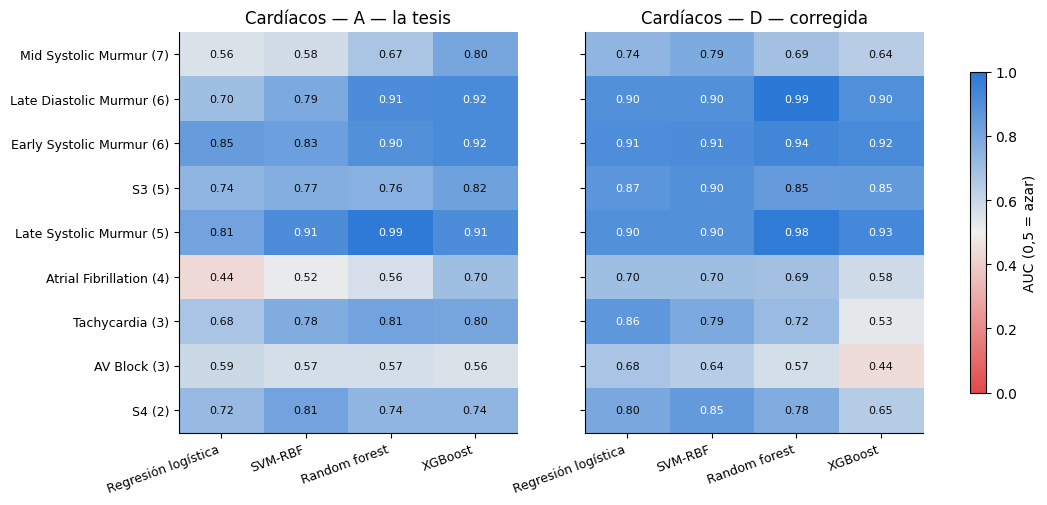

In [14]:
def auc_por_tipo(subset, v):
    X, y, caso, tipo = datos(subset, v)
    normales = tipo == "Normal"
    tipos = pd.Series(tipo[~normales]).value_counts().index
    resultado = {}
    for nombre in MODELOS:
        resultado[nombre] = {}
        for t in tipos:
            etiquetas = np.r_[np.zeros(normales.sum()), np.ones((tipo == t).sum())]
            resultado[nombre][f"{t} ({(tipo == t).sum()})"] = np.mean(
                [roc_auc_score(etiquetas, np.r_[p[normales], p[tipo == t]]) for p in probs[(subset, v, nombre)]])
    return pd.DataFrame(resultado)


MAPA_AUC = LinearSegmentedColormap.from_list("auc", ["#e34948", "#f0efec", AZUL])
ESCALA_AUC = TwoSlopeNorm(vmin=0.0, vcenter=0.5, vmax=1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, v in zip(axes, ["A", "D"]):
    t = auc_por_tipo("HS", v)
    imagen = ax.imshow(t.values, cmap=MAPA_AUC, norm=ESCALA_AUC, aspect="auto")
    ax.set(xticks=range(t.shape[1]), yticks=range(t.shape[0]), title=f"Cardíacos — {ETIQUETA[v]}")
    ax.set_xticklabels(t.columns, rotation=20, ha="right", fontsize=9)
    ax.set_yticklabels(t.index, fontsize=9)
    ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if t.values[i, j] > 0.85 else TINTA)
fig.colorbar(imagen, ax=axes, label="AUC (0,5 = azar)", shrink=0.8)

print("Pulmonares: AUC de cada tipo contra los normales")
print(pd.concat({ETIQUETA[v]: auc_por_tipo("LS", v) for v in ["A", "D"]}, axis=1).round(2).to_string())

**Cómo leerlo (cardíacos):**
- **R3** (S3) mejora con los modelos lineales (regresión logística de 0,74 a
  0,87, SVM-RBF de 0,77 a 0,90). Es lo que anticipaba la notebook 03: el R3 es
  de muy baja frecuencia, y a 4000 Hz hay el doble de bandas mel debajo de
  400 Hz (30 en vez de 15).
- El **soplo mesosistólico** también mejora con los lineales (de ~0,57 a
  ~0,77).
- La **fibrilación auricular** (de 0,44–0,52 a 0,70) y el **bloqueo AV** (de
  0,57–0,59 a 0,64–0,68) mejoran algo con los lineales, pero siguen entre los
  más difíciles. La corrección no les da ritmo a las features: eso es la
  notebook 13.
- XGBoost baja en varios tipos (taquicardia, mesosistólico, bloqueo AV), en
  línea con lo que vimos en la sección 6.

**Pulmonares:** todos los tipos siguen bien separados con los modelos
lineales; los de árboles bajan un poco en algunos (XGBoost en los
crepitantes gruesos).

## 9. La validación por caso, con el control de pseudo-casos

Repetimos el control de las notebooks 07, 09 y 10 con las dos versiones:
validación por caso real (dejar un caso afuera por vez) y por pseudo-casos (5
sorteos de grupos al azar del mismo tamaño y clase). Si el caso real da por
debajo de todos los pseudo-casos, hay fuga. *(Esta celda es la más lenta:
tarda unos 5 minutos.)*

In [15]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


def auc_por_grupos(modelo, X, y, grupos):
    return roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), grupos))


SORTEOS = 5
inicio = time.time()
filas = []
for subset in META:
    for v in ["A", "D"]:
        X, y, caso, tipo = datos(subset, v)
        rng = np.random.default_rng(SEMILLA)
        sorteos = [pseudo_casos(caso, y, rng) for _ in range(SORTEOS)]   # los mismos para las dos versiones
        for nombre, modelo in modelos(y).items():
            pseudo = [auc_por_grupos(modelo, X, y, g) for g in sorteos]
            real = auc_por_grupos(modelo, X, y, caso)
            filas.append({"subconjunto": NOMBRE[subset], "versión": ETIQUETA[v], "modelo": nombre,
                          "por grabación": auc(subset, v, nombre), "pseudo-caso (media)": np.mean(pseudo),
                          "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}",
                          "caso real": real, "¿fuga?": "sí" if real < np.min(pseudo) else "no medible"})
    print(f"{NOMBRE[subset]}: listo")
print(f"({time.time() - inicio:.0f} segundos)")
print(pd.DataFrame(filas).round(3).to_string(index=False))

Pulmonares: listo


Cardíacos: listo
(294 segundos)
subconjunto       versión              modelo  por grabación  pseudo-caso (media) pseudo-caso (mín–máx)  caso real     ¿fuga?
 Pulmonares  A — la tesis Regresión logística          1.000                0.988             0.98–1.00      0.967         sí
 Pulmonares  A — la tesis             SVM-RBF          0.977                0.924             0.90–0.96      0.882         sí
 Pulmonares  A — la tesis       Random forest          0.949                0.857             0.77–0.89      0.755         sí
 Pulmonares  A — la tesis             XGBoost          0.931                0.796             0.77–0.83      0.684         sí
 Pulmonares D — corregida Regresión logística          0.999                0.989             0.98–1.00      0.956         sí
 Pulmonares D — corregida             SVM-RBF          0.975                0.927             0.89–0.97      0.864         sí
 Pulmonares D — corregida       Random forest          0.926                0.837     

**Cómo leerlo:**
- **Pulmonares:** con las dos versiones, la regresión logística y el SVM-RBF
  dan el caso real por debajo de todos los pseudo-casos: hay una fuga real, chica
  en la regresión logística (~0,02–0,03) e intermedia en el SVM-RBF
  (~0,04–0,06). En los modelos de árboles, con la versión corregida la fuga se
  **achica** (random forest de ~0,10 a ~0,07; XGBoost de ~0,11 a ~0,02) y el
  caso real ya cae dentro del rango de los pseudo-casos: con 5 sorteos no
  alcanza para afirmar que haya fuga.
- **Cardíacos:** con las dos versiones, ningún modelo muestra fuga medible. Y
  la regresión logística corregida también es la mejor **validando por caso**:
  pasa de 0,61 a 0,73.

## 10. La nueva línea de base

La versión D queda como la extracción de acá en adelante. La guardamos en
`outputs/` para las notebooks 13 y 14 (la 12 vuelve a extraer, porque los
filtros cambian la señal):

In [16]:
for subset in META:
    destino = OUT_DIR / f"{subset.lower()}_features_corregidas.csv"
    tablas[(subset, "D")].to_csv(destino, index=False)
    print(f"guardada: outputs/{destino.name} ({len(tablas[(subset, 'D')])} grabaciones, "
          f"{tablas[(subset, 'D')].shape[1] - 3} features)")

print("\nLa línea de base (versión corregida, validación por grabación):")
for subset in META:
    print(f"\n{NOMBRE[subset]}")
    print(tabla_metricas(subset, ["D"]).droplevel(0, axis=1).to_string())

guardada: outputs/ls_features_corregidas.csv (50 grabaciones, 101 features)
guardada: outputs/hs_features_corregidas.csv (50 grabaciones, 101 features)

La línea de base (versión corregida, validación por grabación):

Pulmonares


                      AUC    IC 95 %  sens.  esp.  exact. bal.
Regresión logística  1.00  1.00–1.00   1.00  0.86         0.93
SVM-RBF              0.98  0.92–1.00   0.98  0.83         0.91
Random forest        0.93  0.83–0.99   1.00  0.56         0.78
XGBoost              0.87  0.70–0.98   0.91  0.75         0.83

Cardíacos


                      AUC    IC 95 %  sens.  esp.  exact. bal.
Regresión logística  0.83  0.61–0.97   0.86  0.70         0.78
SVM-RBF              0.83  0.62–0.97   0.93  0.41         0.67
Random forest        0.82  0.68–0.94   0.98  0.00         0.49
XGBoost              0.75  0.60–0.89   0.83  0.41         0.62


**Qué nos llevamos:**
1. **La extracción corregida es la base de acá en adelante:** audio a 4000 Hz,
   tramas de 93 ms con saltos de 23 ms, sin relleno, 101 features. Hay que
   pasarla también a los `.py` finales.
2. **Pulmonares:** nada cambia. La regresión logística sigue en ~1,00: el
   resultado de la tesis no dependía de estos errores.
3. **Cardíacos:** los modelos lineales mejoran mucho. La regresión logística
   pasa de estar entre los peores (0,68) a estar arriba (0,83), con la mejor
   exactitud balanceada (0,78). Pero sigue sin haber un ganador claro: los
   cuatro modelos quedan entre 0,75 y 0,83, con intervalos superpuestos.
4. **Lo que sigue pendiente:** las arritmias siguen siendo lo más difícil
   (notebook 13, ritmo) y el random forest sigue sin reconocer normales con el
   umbral 0,5 (notebook 14, umbral).
5. **Para comparar versiones** de acá en adelante usamos el bootstrap pareado
   contra esta línea de base.

## 11. Cómo explicárselo a tu directora (en 5 frases)

1. *"Antes de probar filtros, corregí tres errores de la extracción de
   features: los audios se cargaban a 22.050 Hz aunque están grabados a
   4000 Hz (la mitad de lo que se medía era una zona sin sonido), las tramas
   del borde salían de un relleno de ceros y la planitud espectral daba
   siempre ~0."*
2. *"Para saber qué causó cada cambio, probé cada corrección sola y las dos
   juntas, un diseño 2 × 2, con los mismos cuatro modelos."*
3. *"En pulmonares no cambió nada: el resultado no dependía de esos errores."*
4. *"En cardíacos, la regresión logística mejoró de 0,68 a 0,83 de AUC, una
   mejora real según un bootstrap pareado; los cuatro modelos quedaron
   parecidos, entre 0,75 y 0,83, sin un ganador claro."*
5. *"Los máximos y mínimos de MFCC que parecían importantes no venían del
   relleno: miden sonido real. Los contaminados eran otros, y solo agregaban
   ruido."*

## 12. Tu turno

En la notebook 03 propusimos tramas de 64 ms (256 muestras, con saltos de 64),
y acá elegimos 93 ms para cambiar una sola cosa. ¿Cambia la conclusión con
tramas de 64 ms? Corré la celda y comparalo con la versión D.

Esto **no** es para elegir la trama que mejor dé: es para ver si la
conclusión es **robusta**. Si cambiara mucho con un detalle así, sería una
conclusión frágil. *(Tarda alrededor de un minuto.)*

In [17]:
N_FFT, SALTO = 256, 64   # 64 ms y 16 ms a 4000 Hz

comparacion = {}
for subset, (meta, col_id, col_tipo) in META.items():
    filas = [extraer(audios[(subset, 4000)][fid], 4000, N_FFT, SALTO, bandas_contraste=4, centrar=False)
             for fid in meta[col_id]]
    X = pd.DataFrame(filas)
    y = datos(subset, "D")[1]
    for nombre, modelo in modelos(y).items():
        comparacion[(NOMBRE[subset], nombre)] = {
            f"D (trama de 93 ms)": auc(subset, "D", nombre),
            f"trama de {1000 * N_FFT / 4000:.0f} ms": np.mean([roc_auc_score(y, p) for p in prob_validacion(modelo, X, y)])}
print(pd.DataFrame(comparacion).T.round(3).to_string())

                                D (trama de 93 ms)  trama de 64 ms
Pulmonares Regresión logística               0.999           0.995
           SVM-RBF                           0.975           0.977
           Random forest                     0.926           0.920
           XGBoost                           0.868           0.892
Cardíacos  Regresión logística               0.827           0.837
           SVM-RBF                           0.833           0.857
           Random forest                     0.823           0.815
           XGBoost                           0.752           0.837


**Lo que da:** con tramas de 64 ms, la regresión logística, el SVM-RBF y el
random forest dan prácticamente lo mismo que con 93 ms (en cardíacos, 0,84,
0,86 y 0,82; en pulmonares, ~1,00, 0,98 y 0,92): para ellos, la conclusión
es robusta. XGBoost, en cambio, vuelve a 0,84 en cardíacos: su baja de la
sección 6 depende de un detalle tan arbitrario como la duración de la trama.
Es una muestra de lo frágil que es el resultado de XGBoost con 50
grabaciones, y otro argumento para no elegir la versión según lo que le da
mejor a un modelo.

## Preguntas de control

1. ¿Cuáles son las tres correcciones? ¿Por qué decimos que son errores y no
   decisiones?
2. ¿Por qué elegimos tramas de 372 muestras y no de 256? ¿Qué pasa con las
   bandas del contraste espectral al cargar a 4000 Hz?
3. ¿Qué es un diseño 2 × 2 y qué nos permite saber?
4. ¿Qué es el bootstrap pareado? ¿Por qué es mejor que mirar si se superponen
   los intervalos de cada versión?
5. ¿Qué pasó con los máximos y mínimos de MFCC que parecían importantes en
   cardíacos?
6. ¿Por qué sacar features inútiles ayuda más a la regresión logística que a
   los árboles?
7. XGBoost bajó con la versión corregida. ¿Quiere decir que la versión de la
   tesis era mejor? ¿Por qué no volvemos a ella para XGBoost?
8. ¿Qué tipos de patología cardíaca mejoraron más y cuáles siguen difíciles?
   ¿Por qué?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Cargar los audios a su frecuencia real (4000 Hz) en vez de 22.050 Hz,
con tramas de la misma duración; no rellenar los bordes con ceros
(`center=False`); y, como consecuencia de lo primero, la planitud deja de dar
~0. Son errores porque no hay ningún argumento a favor de medir una zona sin
sonido ni un relleno inventado. Una decisión, como elegir un filtro, tiene
argumentos a favor y en contra. Por eso la versión corregida se adopta de
antemano, sin mirar los resultados.

**2.** Porque 372 muestras a 4000 Hz duran lo mismo que las 2048 de la tesis
a 22.050 Hz (93 ms): así lo único que cambia es la frecuencia de carga, y
además la resolución en frecuencia queda igual (~10,8 Hz). El contraste
divide el espectro en octavas desde 200 Hz: a 22.050 Hz eran 7 bandas, dos
enteras y la mayor parte de otra en la zona vacía; a 4000 Hz entran 5, y la
quinta termina en 2000 Hz.

**3.** Probar cada cambio solo y los dos juntos: cuatro versiones (A, B, C y
D). Comparando cada una con la de la tesis se ve cuánto aporta cada
corrección, y si lo que arreglan se superpone. Si probáramos solo las dos
juntas, no sabríamos cuál causó el cambio.

**4.** Remuestrear las grabaciones y, en cada remuestreo, calcular la
diferencia de AUC entre las dos versiones con las mismas grabaciones; el
intervalo del 95 % de esas diferencias dice si la diferencia puede ser azar
(si incluye el 0). Es mejor porque las dos versiones se evalúan con las mismas
grabaciones: lo que una grabación tiene de difícil afecta a las dos y se
cancela en la diferencia. Mirar los intervalos por separado cuenta esa
variación dos veces.

**5.** La sospecha no se confirmó: los que más separan (`mfcc_5_max`,
`mfcc_4_max` y `mfcc_5_min`) casi nunca salen del borde y separan igual sin
relleno; miden sonido real. Los contaminados eran otros (por ejemplo, el
mínimo de `mfcc_3` sale del relleno en el 94 % de las grabaciones): la tesis
los medía mal y eran ruido para el modelo.

**6.** Porque un árbol elige qué features usar en cada pregunta y puede
ignorar las inútiles. La regresión logística les da un peso a todas, y con
muchas features y pocas grabaciones (p ≫ n), cada feature inútil agrega un
poco de ruido a cada predicción.

**7.** No. A XGBoost le servían más los MFCC de la tesis, pero esa versión
tiene errores: que a un modelo le vaya mejor con un error no lo vuelve
correcto. Elegir la versión según cuál le da mejor a cada modelo sería elegir
mirando los resultados, y el resultado saldría optimista. Además, la baja está
al borde del azar (entre 8 comparaciones) y es frágil: con tramas de 64 ms,
XGBoost vuelve a 0,84 (sección 12). La conclusión general no cambia.

**8.** Mejoraron sobre todo el R3 y el soplo mesosistólico, con los modelos
lineales. El R3 es de muy baja frecuencia, y a 4000 Hz hay el doble de bandas
mel debajo de 400 Hz. Siguen difíciles la fibrilación auricular y el bloqueo
AV: son trastornos del ritmo, y la corrección no les da a las features
información sobre el ritmo (eso es la notebook 13).